# Laboratorio 3 — Re-identificación de personas no supervisada con baja resolución (DRFM)

**Paper:** Pang, Zhao y Wang (2024). *Dual-Resolution Fusion Modeling for Unsupervised Cross-Resolution Person
Re-Identification*. ACM Multimedia '24.  **Dataset:** Market-1501 (6 cámaras).

**Problema.** Dada una imagen de consulta, ordenar una galería por similitud para encontrar a la misma persona en otra
cámara, **sin usar etiquetas de identidad al entrenar**, y evaluar el mismo modelo con consultas originales y con
consultas de baja resolución (32×16).

**Método (DRFM).** Dos encoders ResNet-50 (uno para alta y otro para baja resolución) y tres ideas:
1. **CPG** (generación de pseudo-etiquetas entre resoluciones): se agrupan solo las imágenes HR con DBSCAN y las
   etiquetas se pasan a las imágenes LR multiplicando sus "vectores de clase" en el espacio LR y en el de su versión
   super-resuelta (SHR); solo se conservan las más confiables.
2. **CRFF** (fusión de características): une las características de la misma imagen vistas por los dos encoders.
3. **Pérdidas:** `L_cc` (contraste contra centroides de resolución), `L_ic` (consistencia de identidad, tipo SimSiam)
   y `L_ps` (afilado de probabilidad para las muestras ambiguas).

## Cómo ejecutar
```bash
bash slurm/env_setup.sh                      # entorno + pesos (ResNet-50 ImageNet, Swin2SR) en Khipu
sbatch slurm/prepare_sr_cpu.sbatch           # super-resolución de las imágenes (cache/shr_*.npy)
python -m scripts.calibrar_eps               # calibra DBSCAN con validación
python -m src.train.train_drfm --tag drfm_v2                  # DRFM completo
python -m src.train.train_drfm --tag drfm_sin_crff --sin-crff # ablación
python -m src.train.train_baseline --tag base                 # modelo base
python -m scripts.evaluar_final --particion testing           # métricas en test (una sola vez, al final)
```
Los resultados de este cuaderno se leen de `results/` (generados por esos scripts) y las imágenes de `data/`.

## 0. Diferencias importantes respecto a la propuesta original

| Aspecto | Paper | Esta implementación | Motivo |
|---|---|---|---|
| Datos LR de entrenamiento | MLR-Market-1501: las imágenes de una cámara se reducen ×2, ×3 o ×4 al azar | las cámaras **1, 2 y 5** actúan como "LR" (reducción ×4 bicúbica); **3, 4 y 6** como "HR" | el enunciado pide generar las LR desde las imágenes de entrenamiento; ×4 es exactamente la degradación de las consultas LR del dataset |
| Protocolo de evaluación | consulta LR contra una galería con 1 imagen HR por persona; solo Rank-k | protocolo estándar de Market-1501 (3 368 consultas, 19 732 de galería, *junk* y distractores), mAP y Rank-k, en **dos condiciones** | el enunciado |
| Super-resolución | Swin2SR (checkpoint no indicado) | `caidas/swin2SR-classical-sr-x4-64` | entrenado con degradación bicúbica, igual que el dataset |
| Distancia para DBSCAN | no se indica (solo `min_samples = 4`) | **Jaccard de k-recíprocos** (k1 = 30, k2 = 6), `eps = 0.5` | con distancia coseno DBSCAN junta todo en un cluster con características de ImageNet (F ≤ 0.06, medido en la sección 4) |
| Tamaño de entrada | no se indica | 128×64 (nativo); las LR se reescalan con bicúbica a 128×64; `layer4` con stride 1 | tamaño nativo del dataset |
| Iteraciones por época, schedule de lr | no se indican | 200 iteraciones/época; lr ×0.1 en la época 20 | decisión nuestra (convención de Cluster Contrast) |
| Estabilidad numérica | no se menciona | CRFF en fp32, recorte de gradiente (10), descarte de iteraciones no finitas | la primera corrida divergió a NaN (ver sección 4) |
| Características en test | no se detallan | galería y consultas originales: `f_hsl`; consultas LR: `f_lsh` | inferido de la Sec. 3.3 del paper |
| Entrenamiento final | — | los modelos se entrenan solo con `training.h5`; la configuración y la mejor época se eligen con validación | simplificación; el archivo permitiría reentrenar con las imágenes de validación sin etiquetas |
| Operaciones no implementadas | — | no se usan GNN/AM/CNN del paper original de comparación | no son parte de DRFM |

In [1]:
import inspect, json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()                      # el cuaderno se ejecuta desde la raiz del proyecto
sys.path.insert(0, str(RAIZ))
from src.utils import cargar_config
from src.data.h5data import ampliar_x4_bicubica, cargar_entrenamiento, cargar_particion, reducir_x4

cfg = cargar_config()
RES, DATOS, CACHE = RAIZ / cfg["results_dir"], RAIZ / cfg["data_dir"], RAIZ / cfg["cache_dir"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

## 1. Carga de datos y particiones

`training.h5` solo trae imágenes y cámaras (sin identidades). `validation.h5` y `testing.h5` traen consultas
(originales y de baja resolución) y galería con identidades y cámaras, que se usan **solo para calcular métricas**.

,imágenes de entrenamiento,consultas,galería,personas (consultas),galería: junk (id -1),galería: distractores (id 0)
training.h5,11043,-,-,-,-,-
validation.h5,-,100,1793,100,0,0
testing.h5,-,3368,19732,750,3819,2798


forma de las imágenes: (3, 128, 64) uint8 | consultas LR: (3, 32, 16)


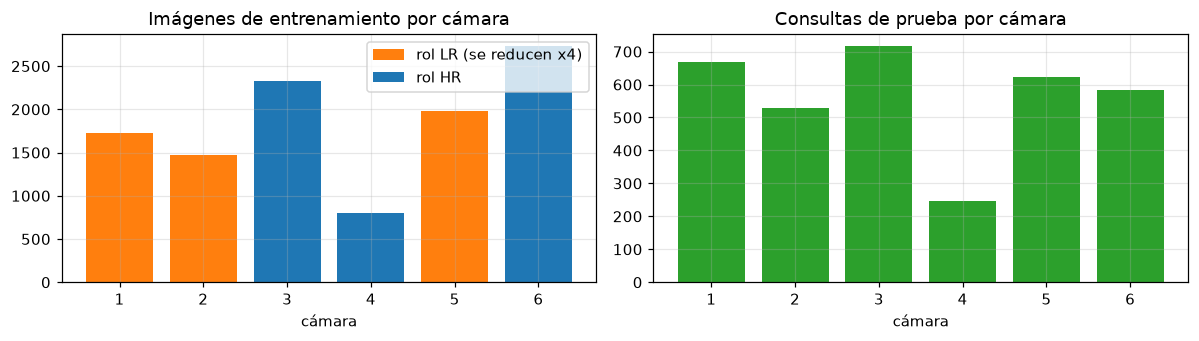

In [2]:
tr = cargar_entrenamiento(DATOS)
val = cargar_particion(DATOS, "validation")
test = cargar_particion(DATOS, "testing")

resumen = pd.DataFrame({
    "imágenes de entrenamiento": [len(tr["images"]), "-", "-"],
    "consultas": ["-", len(val["q_pids"]), len(test["q_pids"])],
    "galería": ["-", len(val["g_pids"]), len(test["g_pids"])],
    "personas (consultas)": ["-", len(np.unique(val["q_pids"])), len(np.unique(test["q_pids"]))],
    "galería: junk (id -1)": ["-", int((val["g_pids"] == -1).sum()), int((test["g_pids"] == -1).sum())],
    "galería: distractores (id 0)": ["-", int((val["g_pids"] == 0).sum()), int((test["g_pids"] == 0).sum())],
}, index=["training.h5", "validation.h5", "testing.h5"])
display(resumen)
print("forma de las imágenes:", tr["images"].shape[1:], tr["images"].dtype, "| consultas LR:", test["q_images_lr"].shape[1:])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
cams, cuenta = np.unique(tr["camera_ids"], return_counts=True)
roles = np.isin(cams, cfg["lr_cameras"])
ax[0].bar(cams[roles], cuenta[roles], color="tab:orange", label="rol LR (se reducen x4)")
ax[0].bar(cams[~roles], cuenta[~roles], color="tab:blue", label="rol HR")
ax[0].set_title("Imágenes de entrenamiento por cámara"); ax[0].set_xlabel("cámara"); ax[0].legend()
cams_t, cuenta_t = np.unique(test["q_cams"], return_counts=True)
ax[1].bar(cams_t, cuenta_t, color="tab:green"); ax[1].set_title("Consultas de prueba por cámara"); ax[1].set_xlabel("cámara")
plt.tight_layout(); plt.show()

## 2. Preprocesamiento y transformaciones

Para cada imagen de entrenamiento se construyen tres versiones (todas de 128×64):

* **original** `X`;
* **SLR / LR "borrosa"** `X_deg`: reducida ×4 con bicúbica y vuelta a ampliar (lo que ve el encoder LR);
* **SHR**: la imagen reducida ×4 pasada por **Swin2SR** (lo que ve el encoder HR cuando la imagen es LR).

Cada imagen juega **un solo rol según su cámara** (el paper ata la resolución a la cámara): las de cámaras `lr_cameras`
solo se usan como par (LR, SHR) — su original nunca entra al modelo — y las demás como par (HR, SLR).

Aumentación: volteo horizontal y recorte aleatorio, aplicados **igual a las dos imágenes de cada par** (CRFF fusiona dos
vistas de la misma imagen y deben estar alineadas).

diferencia máxima entre 'bicúbica x4 de PIL' y la LR del dataset (consultas de validación): 0


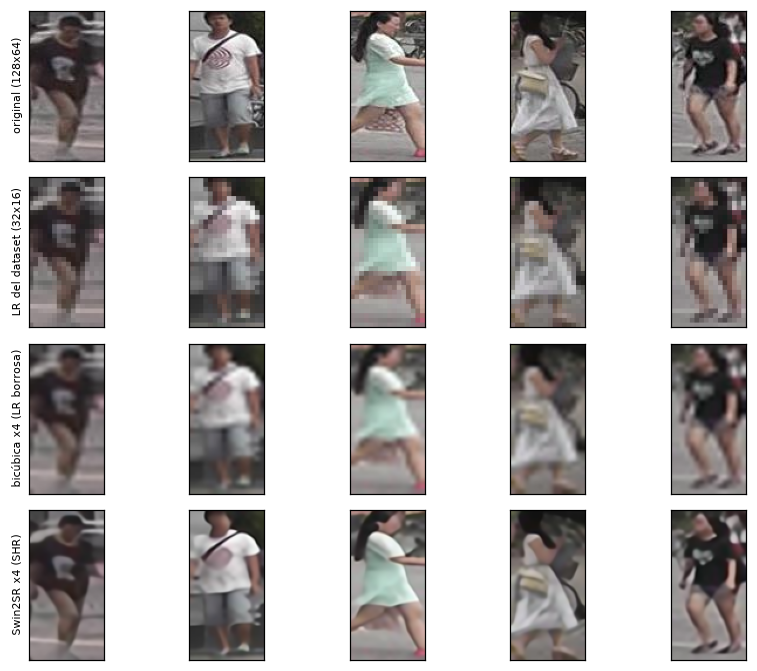

Swin2SR cargada en cpu
train: (11043, 3, 128, 64) en 665s

PSNR frente al original (train, 11043 imagenes):
  ampliacion bicubica : 24.02 dB
  Swin2SR x4          : 26.57 dB
PSNR consultas de prueba: bicubica 23.85 dB | Swin2SR 26.25 dB
cache guardada en /home/eros.aranibar/lab3/cache



In [3]:
# 1) La version LR que trae el dataset es EXACTAMENTE la bicubica x4 de PIL -> podemos generar las LR de entrenamiento igual
n = 200
dif = np.abs(reducir_x4(val["q_images"][:n]).astype(int) - val["q_images_lr"][:n].astype(int)).max()
print(f"diferencia máxima entre 'bicúbica x4 de PIL' y la LR del dataset (consultas de validación): {dif}")

# 2) Cuatro vistas de las mismas imágenes
shr_val_q = np.load(CACHE / "shr_val_q.npy")
idx = [0, 7, 21, 40, 63]
filas = {
    "original (128x64)": val["q_images"][idx],
    "LR del dataset (32x16)": val["q_images_lr"][idx],
    "bicúbica x4 (LR borrosa)": ampliar_x4_bicubica(val["q_images_lr"][idx]),
    "Swin2SR x4 (SHR)": shr_val_q[idx],
}
fig, ax = plt.subplots(len(filas), len(idx), figsize=(1.6 * len(idx), 3.1 * len(filas) / 2))
for r, (nombre, ims) in enumerate(filas.items()):
    for c in range(len(idx)):
        im = ims[c].transpose(1, 2, 0)
        if im.shape[0] == 32:                         # la LR de 32x16 se muestra con tamano real aumentado sin suavizar
            im = np.kron(im, np.ones((4, 4, 1), dtype=np.uint8))
        ax[r, c].imshow(im); ax[r, c].set_xticks([]); ax[r, c].set_yticks([]); ax[r, c].grid(False)
    ax[r, 0].set_ylabel(nombre, fontsize=7)
plt.tight_layout(); plt.show()
print(open(RES / "prepare_sr_log.txt", encoding="utf8").read())

## 3. Implementación del método del paper

El código está en `src/`. Estas son las piezas centrales, con su correspondencia con el paper:

| Pieza | Archivo | Ecuaciones del paper |
|---|---|---|
| CPG (pseudo-etiquetas entre resoluciones) | `src/cluster/cpg.py` | 4 – 9 |
| CRFF (fusión de características) | `src/models/crff.py` | 10 – 13 |
| Memoria y centroides de resolución | `src/memory.py` | 1 – 3, 14 – 15 |
| `L_cc`, `L_ic`, `L_ps` | `src/losses/drfm_losses.py` | 16, 18, 19 |
| Distancia Jaccard de k-recíprocos (nuestra) | `src/cluster/jaccard.py` | — (usada por DBSCAN) |
| Bucle de entrenamiento | `src/train/train_drfm.py` | 20 |

Pruebas con datos sintéticos (`tests/`): `L_cc` coincide con una implementación ingenua con bucles de la Ec. 16; CPG recupera
las identidades; el Jaccard por bloques coincide con el algoritmo original de re-ranking (error 1e-7).

In [4]:
from src.cluster.cpg import generar_pseudoetiquetas
from src.models.crff import CRFF
print(inspect.getsource(generar_pseudoetiquetas))
print(inspect.getsource(CRFF))

@torch.no_grad()
def generar_pseudoetiquetas(f_h, f_sl, etiquetas_h, f_l, f_sh, tau_l, tau_h, t):
    """Pseudo-etiquetas para las imagenes LR a partir de los clusters de las HR.

    f_h, f_sl : caracteristicas (normalizadas) de las HR y de sus SLR   (N1, D)
    etiquetas_h: clusters de las HR por DBSCAN (-1 = sin cluster)       (N1,) tensor
    f_l, f_sh : caracteristicas (normalizadas) de las LR y de sus SHR   (N2, D)
    Devuelve etiquetas para las N2 imagenes LR (-1 = ambigua) y la confianza de cada una.
    """
    K = int(etiquetas_h.max().item()) + 1
    C_h = centroides_por_cluster(f_h, etiquetas_h, K)       # Ec. 7: centroides HR (espacio HR)
    C_sl = centroides_por_cluster(f_sl, etiquetas_h, K)     # Ec. 5: centroides SLR (espacio LR); la SLR hereda el cluster de su HR

    # Ec. 4 y 6: "vector de clase" = a que cluster se parece cada imagen (en logaritmo, por estabilidad)
    log_s_l = F.log_softmax(f_l @ C_sl.T / tau_l, dim=1)     # la LR, vista en el espacio LR
    log_

In [5]:
from src.losses.drfm_losses import afilado_probabilidad, consistencia_identidad, contraste_entre_resoluciones
for f in (contraste_entre_resoluciones, consistencia_identidad, afilado_probabilidad):
    print(inspect.getsource(f))

def contraste_entre_resoluciones(f, clusters, C, presente, n_neg, tau):
    """L_cc (Ec. 16): una especie de InfoNCE contra CENTROIDES en lugar de contra muestras.

    Para cada caracteristica `f`:
      * positivos: los centroides de resolucion de SU cluster (1 o 2, uno por tipo);
      * negativos: los `n_neg` centroides mas parecidos de OTROS clusters;
    y se maximiza la probabilidad de los positivos frente al conjunto positivos + negativos.
    f: (B, D); clusters: (B,) cluster de cada muestra; C: (K, 2, D); presente: (K, 2)
    """
    f = F.normalize(f, dim=1)
    K = C.shape[0]
    valido = presente.reshape(-1)                              # (2K,) centroides que existen
    sim = (f @ C.reshape(K * 2, -1).T) / tau                   # (B, 2K) similitud / temperatura
    sim = sim.masked_fill(~valido, NEG_INF)

    pos = (torch.arange(K * 2, device=f.device).unsqueeze(0) // 2) == clusters.unsqueeze(1)
    pos = pos & valido                                         # (B, 2K): cen

In [6]:
import torch
from src.models.drfm import DRFM
m = DRFM(preentrenado=False)
cuenta = lambda mod: sum(p.numel() for p in mod.parameters()) / 1e6
print(f"E_h: {cuenta(m.E_h):.1f} M | E_l: {cuenta(m.E_l):.1f} M | CRFF: {cuenta(m.crff):.1f} M | Pred: {cuenta(m.pred):.1f} M | total: {cuenta(m):.1f} M parámetros")
del m

E_h: 23.5 M | E_l: 23.5 M | CRFF: 16.8 M | Pred: 4.2 M | total: 68.0 M parámetros


## 4. Entrenamiento y validación

**Protocolo.** 40 épocas de 200 iteraciones; lotes de 16 clusters × 4 imágenes = 64; Adam (lr 3.5·10⁻⁴, decaimiento 5·10⁻⁴);
`L_ps` entra después de la época 10 con λ = 1.5; temperaturas y demás hiperparámetros del paper (ver `configs/base.yaml`).
En cada época: (1) se extraen las características de todas las imágenes, (2) DBSCAN sobre las HR, (3) CPG pasa las
pseudo-etiquetas a las LR, (4) se llenan las memorias y (5) se entrena. **La configuración y la mejor época se eligen con
la partición de validación** (100 consultas, 1 793 de galería).

### 4.1 Calibración de DBSCAN con validación
El paper solo indica `min_samples = 4`. Con las imágenes de validación (donde sí conocemos las identidades) medimos la calidad de
los clusters que produce el ResNet-50 sin entrenar, por pares de imágenes (precisión = pares juntados que son la misma persona,
recall = pares de la misma persona que quedaron juntos, F = su media armónica):

In [7]:
print(open(RES / "calibrar_eps.txt", encoding="utf8").read())

1893 imagenes de validacion, 100 personas reales
cos. medio entre imagenes distintas (sin centrar): 0.716

(a) coseno sin centrar, eps fijo
configuracion               clusters  agrupadas  precision   recall      F
eps=0.02                   (ningun cluster)
eps=0.04                   (ningun cluster)
eps=0.06                           3       0.01       0.89     0.00   0.00
eps=0.08                           8       0.06       0.19     0.02   0.03
eps=0.1                            9       0.19       0.03     0.06   0.05
eps=0.12                           5       0.46       0.02     0.26   0.03
eps=0.14                           6       0.67       0.02     0.49   0.03

(b) coseno CENTRADO, eps fijo
configuracion               clusters  agrupadas  precision   recall      F
centrado eps=0.3                   6       0.03       0.37     0.01   0.02
centrado eps=0.4                  23       0.16       0.09     0.05   0.06
centrado eps=0.5                  14       0.60       0.02     0.4

Con **distancia coseno** (con o sin centrar) todas las configuraciones dan F ≤ 0.06: DBSCAN "encadena" y agrupa casi todo en un
solo cluster, porque las características de ResNet salen de una ReLU y todos los cosenos son altos (media 0.72). La
**distancia Jaccard de k-recíprocos** exige que dos imágenes sean vecinas mutuas, lo que corta el encadenamiento (F = 0.14 con
`eps = 0.55`, precisión 0.53 con `eps = 0.4`). Usamos `eps = 0.5`, un punto intermedio.

### 4.2 Primera corrida de DRFM: divergencia a NaN
La primera corrida de DRFM completo dio `Lcc = NaN` desde la época 3 y quedó estancada (mAP ≈ 10 durante 38 épocas), mientras que la
ablación sin CRFF y el modelo base entrenaban bien. La diferencia entre ambos es solo el camino de fusión. Nuestra explicación más probable: el producto
`F1(f)·F2(f)` de CRFF llegaba a ≈ 38 000 sobre imágenes de validación (el máximo de fp16 es 65 504, de modo que en entrenamiento, con
aumentación, puede desbordarse), y un NaN escrito en la memoria de centroides contamina todas las pérdidas siguientes. **No logramos
reproducir el desborde exacto** con el checkpoint final, así que esto es una hipótesis compatible con las medidas, no una demostración;
lo que sí está comprobado es que las correcciones eliminaron el NaN. Correcciones: CRFF en fp32, la memoria rechaza valores no finitos,
se descartan las iteraciones con pérdida no finita (y se cuentan), y se recorta la norma del gradiente. Las corridas corregidas registran
`saltadas` y `nofinitas` en cada época. La corrida fallida se conserva como evidencia (`drfm_historial.json`).

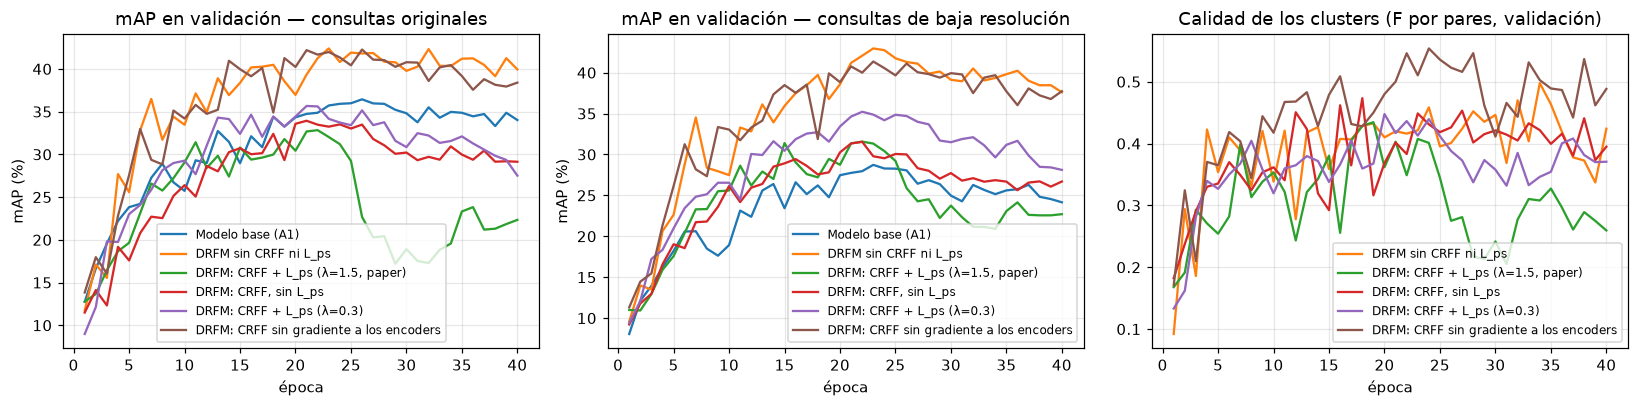

Primera corrida de DRFM (NaN): épocas con Lcc = NaN: 38 de 40; mAP original máximo en validación: 11.6


In [8]:
def cargar_hist(nombre):
    return json.load(open(RES / f"{nombre}_historial.json"))

CANDIDATOS = {"base": ("Modelo base (A1)", None),
              "drfm_sin_crff": ("DRFM sin CRFF ni L_ps", "sin_fusion"),
              "drfm_v2": ("DRFM: CRFF + L_ps (λ=1.5, paper)", "fusion"),
              "drfm_sin_ps": ("DRFM: CRFF, sin L_ps", "fusion"),
              "drfm_lps03": ("DRFM: CRFF + L_ps (λ=0.3)", "fusion"),
              "drfm_detach": ("DRFM: CRFF sin gradiente a los encoders", "fusion")}
H = {nombre: (arch, clave) for arch, (nombre, clave) in CANDIDATOS.items() if (RES / f"{arch}_historial.json").exists()}
hist = {n: cargar_hist(f) for n, (f, _) in H.items()}

def serie(nombre, cond):
    f, clave = H[nombre]
    h = [e for e in hist[nombre] if "val" in e]
    v = [(e["val"][clave] if clave else e["val"])[cond]["mAP"] for e in h]
    return [e["epoca"] for e in h], v

COLOR = {n: f"C{i}" for i, n in enumerate(H)}          # un color fijo por modelo en los tres graficos
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for n in H:
    ax[0].plot(*serie(n, "original"), label=n, color=COLOR[n]); ax[1].plot(*serie(n, "baja_resolucion"), label=n, color=COLOR[n])
ax[0].set_title("mAP en validación — consultas originales"); ax[1].set_title("mAP en validación — consultas de baja resolución")
for a in ax[:2]: a.set_xlabel("época"); a.set_ylabel("mAP (%)"); a.legend(fontsize=8)
for n in [n for n in H if n.startswith("DRFM")]:
    h = [e for e in hist[n] if "val_clusters" in e]
    ax[2].plot([e["epoca"] for e in h], [e["val_clusters"]["F"] for e in h], label=n, color=COLOR[n])
ax[2].set_title("Calidad de los clusters (F por pares, validación)"); ax[2].set_xlabel("época"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

# primera corrida fallida (NaN) para comparar
h1 = [e for e in cargar_hist("drfm") if "val" in e]
print("Primera corrida de DRFM (NaN): épocas con Lcc = NaN:", sum(1 for e in cargar_hist("drfm") if e.get("L_cc") != e.get("L_cc")), "de 40;",
      "mAP original máximo en validación:", round(max(e["val"]["fusion"]["original"]["mAP"] for e in h1), 1))

In [9]:
filas = []
for n, (f, clave) in H.items():
    h = [e for e in hist[n] if "val" in e]
    mejor = max(h, key=lambda e: 0.5 * ((e["val"][clave] if clave else e["val"])["original"]["mAP"] + (e["val"][clave] if clave else e["val"])["baja_resolucion"]["mAP"]))
    v = mejor["val"][clave] if clave else mejor["val"]
    filas.append({"modelo": n, "mejor época": mejor["epoca"],
                  "mAP orig": v["original"]["mAP"], "R1 orig": v["original"]["Rank-1"],
                  "mAP LR": v["baja_resolucion"]["mAP"], "R1 LR": v["baja_resolucion"]["Rank-1"], "caída mAP": v["caida_mAP"]})
zs = json.load(open(RES / "zero_shot_validation.json"))
filas.insert(0, {"modelo": "ResNet-50 sin entrenar", "mejor época": "-", "mAP orig": zs["original"]["mAP"], "R1 orig": zs["original"]["Rank-1"],
                 "mAP LR": zs["baja_resolucion"]["mAP"], "R1 LR": zs["baja_resolucion"]["Rank-1"], "caída mAP": zs["caida_mAP"]})
print("Validación (100 consultas, 1 793 de galería) — se elige la época con mejor mAP medio de las dos condiciones")
display(pd.DataFrame(filas).round(1).set_index("modelo"))

Validación (100 consultas, 1 793 de galería) — se elige la época con mejor mAP medio de las dos condiciones


,mejor época,mAP orig,R1 orig,mAP LR,R1 LR,caída mAP
modelo,,,,,,
ResNet-50 sin entrenar,-,9.5,18.0,6.9,15.0,2.6
Modelo base (A1),26,36.4,52.0,28.1,38.0,8.4
DRFM sin CRFF ni L_ps,23,42.4,67.0,43.0,67.0,-0.6
"DRFM: CRFF + L_ps (λ=1.5, paper)",22,32.8,60.0,31.6,56.0,1.3
"DRFM: CRFF, sin L_ps",21,33.9,54.0,31.3,51.0,2.6
DRFM: CRFF + L_ps (λ=0.3),22,35.6,57.0,35.2,57.0,0.4
DRFM: CRFF sin gradiente a los encoders,26,42.3,62.0,41.1,61.0,1.2


## 5. Evaluación en la partición de prueba (ambas condiciones)

Mismo modelo entrenado para las dos condiciones, vectores normalizados L2 y similitud coseno. Condición **original**:
consultas y galería en resolución original. Condición **baja resolución**: consultas de 32×16 (con la galería original).
La partición de prueba se evaluó **una sola vez**, después de fijar la configuración y la mejor época con validación.
Protocolo estándar de Market-1501: se descartan de la galería las imágenes *junk* y las de la misma persona y misma cámara que la consulta.

PRUEBA: 3368 consultas | columnas sin sufijo = imágenes originales; (LR) = consultas de baja resolución


,mAP,Rank-1,Rank-5,Rank-10,mAP (LR),Rank-1 (LR),Rank-5 (LR),Rank-10 (LR),caída de mAP
modelo,,,,,,,,,
ResNet-50 sin entrenar,2.5,7.8,16.8,22.8,1.4,4.2,10.4,15.0,1.1
Modelo base (A1),13.6,30.0,45.7,52.9,8.3,14.3,29.8,37.9,5.4
DRFM CRFF + L_ps (λ=0.3) ★ elegido — con fusión,13.2,28.1,45.5,54.0,12.7,25.8,43.9,52.6,0.5
DRFM CRFF + L_ps (λ=0.3) ★ elegido — sin fusión (solo encoder HR),14.0,30.6,48.1,56.7,13.4,28.0,46.1,55.3,0.6
"DRFM CRFF + L_ps (λ=1.5, paper) — con fusión",12.3,27.4,45.3,54.6,11.5,24.2,41.8,50.9,0.9
"DRFM CRFF + L_ps (λ=1.5, paper) — sin fusión (solo encoder HR)",12.5,29.6,46.8,55.8,11.3,24.6,42.4,51.3,1.2
"DRFM CRFF, sin L_ps — con fusión",12.4,28.5,46.2,55.5,11.6,25.1,44.1,51.7,0.8
"DRFM CRFF, sin L_ps — sin fusión (solo encoder HR)",13.5,31.4,50.4,58.5,12.3,27.9,45.5,54.0,1.3
DRFM CRFF sin gradiente a los encoders — con fusión,17.8,34.5,53.8,62.2,17.1,32.2,51.8,60.3,0.7


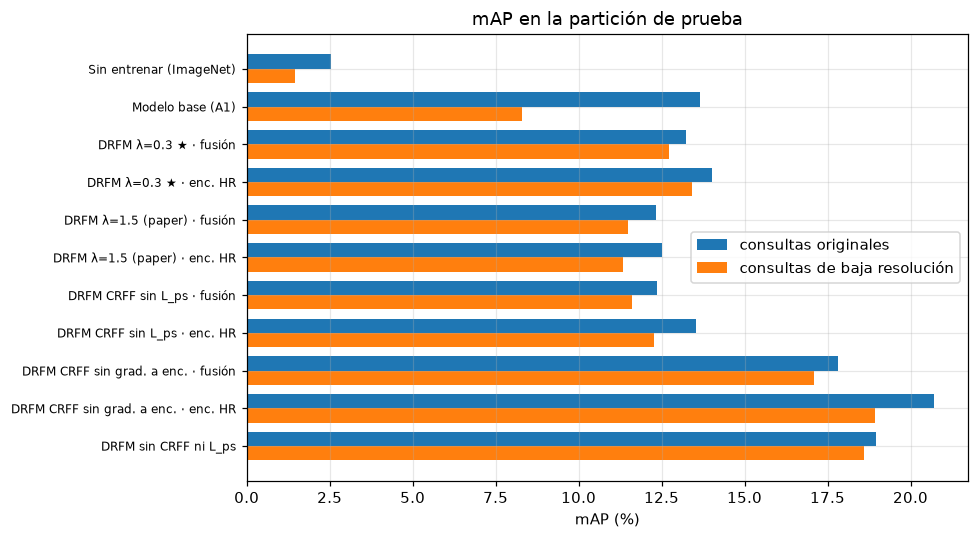

In [10]:
R = json.load(open(RES / "resultados_testing.json"))
META = R.pop("_meta")
PRINCIPAL = META["principal"]                       # el DRFM elegido con validacion
TAGS = {"drfm_v2": "CRFF + L_ps (λ=1.5, paper)", "drfm_sin_ps": "CRFF, sin L_ps", "drfm_lps03": "CRFF + L_ps (λ=0.3)",
        "drfm_detach": "CRFF sin gradiente a los encoders", "drfm_sin_crff": "sin CRFF ni L_ps"}
NOMBRES = {"zero_shot": "ResNet-50 sin entrenar", "base": "Modelo base (A1)"}
for k in R:
    if k.endswith("__fusion"):
        t = k[:-8]; NOMBRES[k] = f"DRFM {TAGS.get(t, t)}" + (" ★ elegido" if t == PRINCIPAL else "") + " — con fusión"
    elif k.endswith("__sin_fusion"):
        t = k[:-12]; NOMBRES[k] = f"DRFM {TAGS.get(t, t)}" + (" ★ elegido" if t == PRINCIPAL else "") + (" — sin fusión (solo encoder HR)" if t != "drfm_sin_crff" else "")
filas = []
for k, nombre in NOMBRES.items():
    if k not in R: continue
    o, l = R[k]["original"], R[k]["baja_resolucion"]
    filas.append({"modelo": nombre, "mAP": o["mAP"], "Rank-1": o["Rank-1"], "Rank-5": o["Rank-5"], "Rank-10": o["Rank-10"],
                  "mAP (LR)": l["mAP"], "Rank-1 (LR)": l["Rank-1"], "Rank-5 (LR)": l["Rank-5"], "Rank-10 (LR)": l["Rank-10"],
                  "caída de mAP": R[k]["caida_mAP"]})
tabla = pd.DataFrame(filas).set_index("modelo")
print(f"PRUEBA: {R['zero_shot']['original']['n_consultas']} consultas | columnas sin sufijo = imágenes originales; (LR) = consultas de baja resolución")
display(tabla.round(1))

def corto(k):
    """Etiqueta corta para los graficos."""
    if k == "zero_shot": return "Sin entrenar (ImageNet)"
    if k == "base": return "Modelo base (A1)"
    t, v = k.rsplit("__", 1)
    et = {"drfm_v2": "λ=1.5 (paper)", "drfm_sin_ps": "CRFF sin L_ps", "drfm_lps03": "λ=0.3 ★",
          "drfm_detach": "CRFF sin grad. a enc.", "drfm_sin_crff": "sin CRFF ni L_ps"}.get(t, t)
    return f"DRFM {et}" + (" · fusión" if v == "fusion" else (" · enc. HR" if t != "drfm_sin_crff" else ""))
CLAVES = [k for k in NOMBRES if k in R]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(CLAVES))[::-1]; h = 0.38
ax.barh(y + h / 2, [R[k]["original"]["mAP"] for k in CLAVES], h, label="consultas originales")
ax.barh(y - h / 2, [R[k]["baja_resolucion"]["mAP"] for k in CLAVES], h, label="consultas de baja resolución")
ax.set_yticks(y); ax.set_yticklabels([corto(k) for k in CLAVES], fontsize=8); ax.set_xlabel("mAP (%)")
ax.set_title("mAP en la partición de prueba"); ax.legend(); plt.tight_layout(); plt.show()

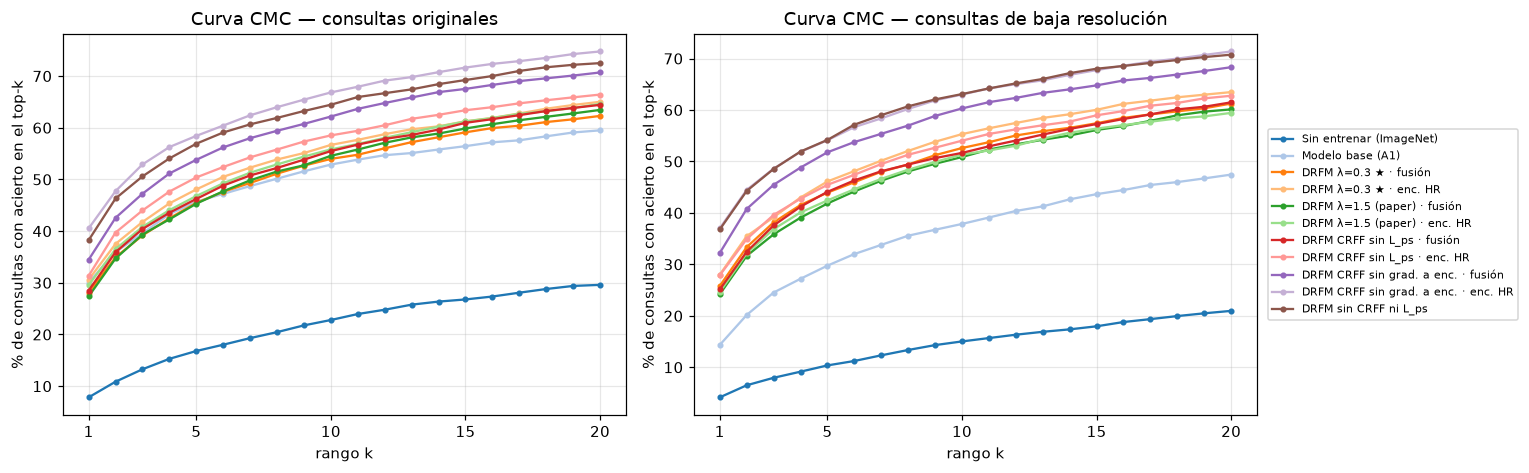

In [11]:
det = np.load(RES / "detalle_testing.npz")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for cond, a in zip(("original", "baja_resolucion"), ax):
    for i, k in enumerate(CLAVES):
        if f"{k}__{cond}__primer_acierto" not in det: continue
        p = det[f"{k}__{cond}__primer_acierto"]
        cmc = [100 * np.mean(p < r) for r in range(1, 21)]
        a.plot(range(1, 21), cmc, marker="o", ms=3, color=plt.cm.tab20(i), label=corto(k))
    a.set_title("Curva CMC — " + ("consultas originales" if cond == "original" else "consultas de baja resolución"))
    a.set_xlabel("rango k"); a.set_ylabel("% de consultas con acierto en el top-k"); a.set_xticks([1, 5, 10, 15, 20])
ax[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()

## 6. Comparación con el modelo base y estudio de ablación

**Modelo base** = el paso A1 de la Tabla 3 del paper: un solo encoder, DBSCAN directo sobre *todas* las imágenes (HR y LR
mezcladas, sin CPG) y pérdida softmax sobre las pseudo-etiquetas; mismo presupuesto de entrenamiento que DRFM.

**Ablación.** Componente estudiado: **CRFF** (la fusión). Se entrena DRFM *sin* CRFF: se mantienen CPG, `L_cc` (en los espacios HR y LR) y `L_ic`;
se quitan el módulo de fusión y, con él, `L_ps` (que opera sobre la característica fusionada). Además, evaluando el DRFM completo
usando solo el encoder HR (sin fusión) se separa el efecto de la fusión **en la inferencia** del efecto de haber **entrenado** con ella.

In [12]:
t = tabla
base = t.loc["Modelo base (A1)"]
mejora = (t[["mAP", "Rank-1", "mAP (LR)", "Rank-1 (LR)"]] - base[["mAP", "Rank-1", "mAP (LR)", "Rank-1 (LR)"]]).round(1)
mejora.columns = ["Δ mAP", "Δ Rank-1", "Δ mAP (LR)", "Δ Rank-1 (LR)"]
print("Diferencia frente al modelo base (puntos porcentuales):")
display(mejora)

Diferencia frente al modelo base (puntos porcentuales):


,Δ mAP,Δ Rank-1,Δ mAP (LR),Δ Rank-1 (LR)
modelo,,,,
ResNet-50 sin entrenar,-11.1,-22.2,-6.8,-10.2
Modelo base (A1),0.0,0.0,0.0,0.0
DRFM CRFF + L_ps (λ=0.3) ★ elegido — con fusión,-0.4,-1.9,4.4,11.5
DRFM CRFF + L_ps (λ=0.3) ★ elegido — sin fusión (solo encoder HR),0.4,0.6,5.1,13.7
"DRFM CRFF + L_ps (λ=1.5, paper) — con fusión",-1.3,-2.7,3.2,9.9
"DRFM CRFF + L_ps (λ=1.5, paper) — sin fusión (solo encoder HR)",-1.1,-0.5,3.0,10.3
"DRFM CRFF, sin L_ps — con fusión",-1.3,-1.5,3.3,10.8
"DRFM CRFF, sin L_ps — sin fusión (solo encoder HR)",-0.1,1.3,4.0,13.5
DRFM CRFF sin gradiente a los encoders — con fusión,4.2,4.4,8.8,17.9


## 7. Análisis de errores

Se analiza el **DRFM elegido con validación** (con fusión) en la condición de **baja resolución** (la más difícil).

In [13]:
M = f"{PRINCIPAL}__fusion"
ap_o, ap_l = det[f"{M}__original__ap"], det[f"{M}__baja_resolucion__ap"]
pr_o, pr_l = det[f"{M}__original__primer_acierto"], det[f"{M}__baja_resolucion__primer_acierto"]
top_l = det[f"{M}__baja_resolucion__top"]
q_pids, q_cams, g_pids, g_cams = test["q_pids"], test["q_cams"], test["g_pids"], test["g_cams"]

ok_o, ok_l = pr_o == 0, pr_l == 0
print(f"Rank-1 original: {100 * ok_o.mean():.1f}% | Rank-1 baja resolución: {100 * ok_l.mean():.1f}%")
print(pd.DataFrame({"consultas": [int((ok_o & ok_l).sum()), int((ok_o & ~ok_l).sum()), int((~ok_o & ok_l).sum()), int((~ok_o & ~ok_l).sum())]},
                   index=["aciertan en ambas", "aciertan solo con original (la baja resolución las rompe)", "aciertan solo con baja resolución", "fallan en ambas"]))

# Rank-1 por camara de la consulta
por_cam = pd.DataFrame({"consultas": [int((q_cams == c).sum()) for c in range(1, 7)],
                        "Rank-1 original": [100 * ok_o[q_cams == c].mean() for c in range(1, 7)],
                        "Rank-1 LR": [100 * ok_l[q_cams == c].mean() for c in range(1, 7)],
                        "mAP LR": [100 * ap_l[q_cams == c].mean() for c in range(1, 7)]}, index=range(1, 7)).round(1)
por_cam.index.name = "cámara de la consulta"
display(por_cam)

# ¿Qué es lo que se recupera en primer lugar cuando se falla? (condición baja resolución)
falla = ~ok_l
t1 = top_l[falla, 0]
tipo = np.where(g_pids[t1] == 0, "distractor (persona fuera de las 750)", "otra persona")
misma_cam = g_cams[t1] == q_cams[falla]
print("\nCuando el top-1 es incorrecto (baja resolución):")
print(pd.Series(tipo).value_counts().to_string())
print(f"  top-1 incorrecto tomado de la MISMA cámara que la consulta: {100 * misma_cam.mean():.1f}%")
print(f"  consultas sin ningún acierto en el top-10: {100 * (pr_l >= 10).mean():.1f}% ({int((pr_l >= 10).sum())})")

Rank-1 original: 28.1% | Rank-1 baja resolución: 25.8%
                                                    consultas
aciertan en ambas                                         662
aciertan solo con original (la baja resolución ...        285
aciertan solo con baja resolución                         207
fallan en ambas                                          2214


,consultas,Rank-1 original,Rank-1 LR,mAP LR
cámara de la consulta,,,,
1,668,26.9,24.0,12.5
2,530,29.4,25.8,14.3
3,717,34.2,34.4,15.6
4,248,34.3,31.0,14.6
5,622,34.6,31.7,14.2
6,583,11.3,8.7,5.8



Cuando el top-1 es incorrecto (baja resolución):
otra persona                             2212
distractor (persona fuera de las 750)     287
  top-1 incorrecto tomado de la MISMA cámara que la consulta: 43.1%
  consultas sin ningún acierto en el top-10: 47.4% (1596)


aciertos (consulta, cámara): [(1570, 3), (2238, 1), (153, 2), (164, 4), (980, 5)]
fallos   (consulta, cámara): [(1084, 4), (1363, 3), (1698, 2), (3351, 6), (76, 5)]


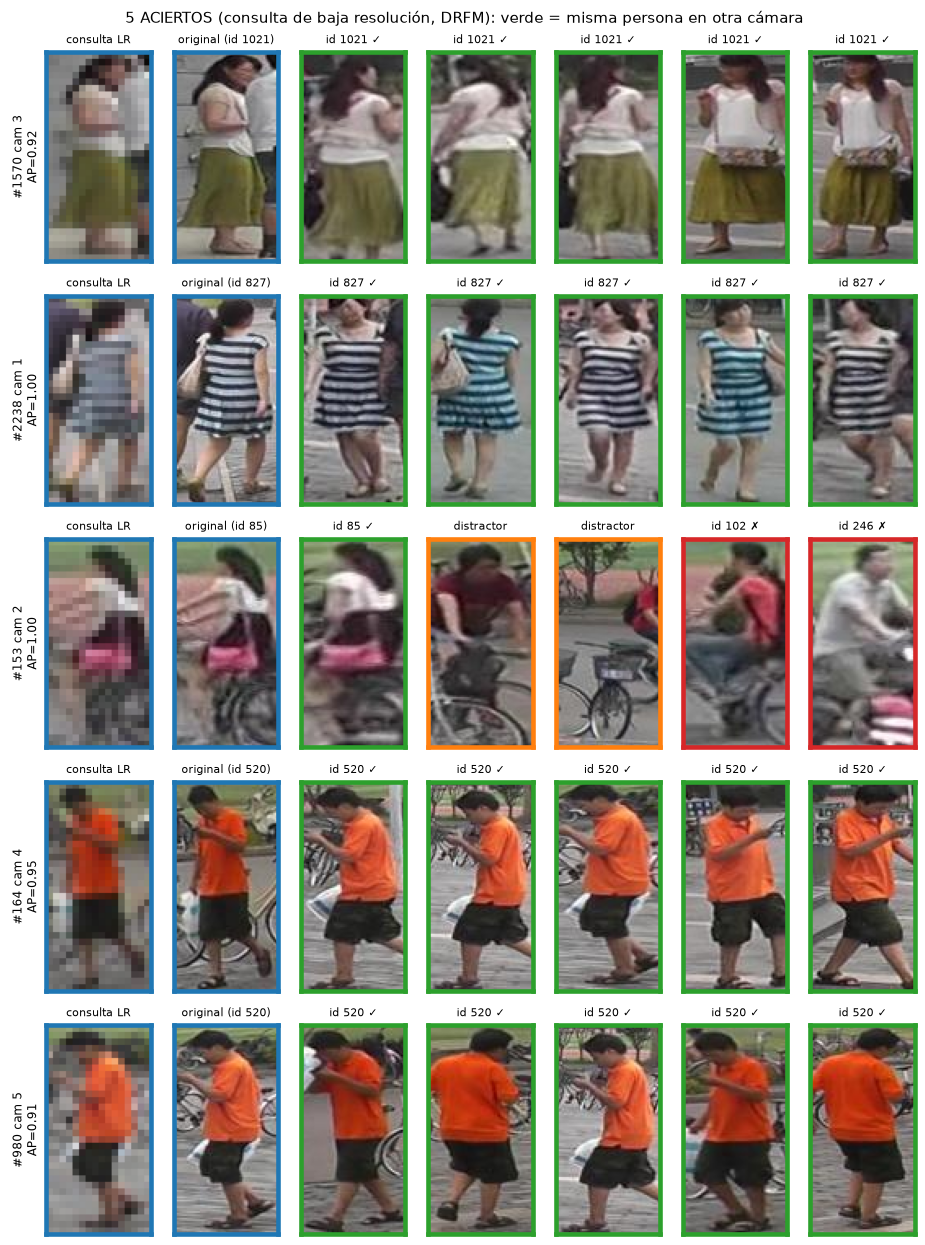

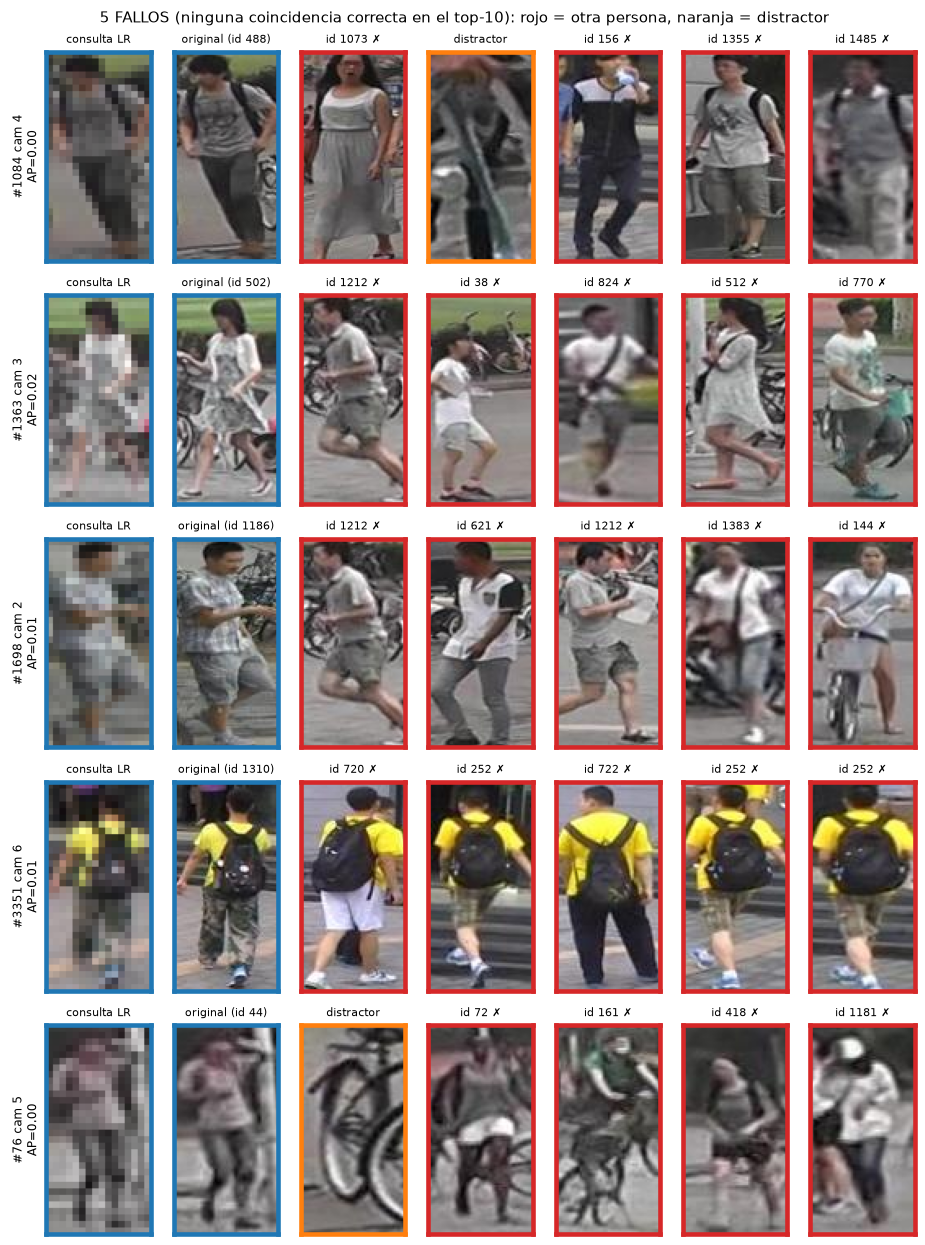

In [14]:
rng = np.random.default_rng(7)
def elegir(mask, n=5):
    """Elige n consultas de `mask` con camaras distintas."""
    idx, usadas = [], set()
    for i in rng.permutation(np.flatnonzero(mask)):
        if q_cams[i] not in usadas:
            idx.append(int(i)); usadas.add(q_cams[i])
        if len(idx) == n: break
    return idx

aciertos = elegir(ok_l & (ap_l >= 0.9))
fallos = elegir(pr_l >= 10)
print("aciertos (consulta, cámara):", [(i, int(q_cams[i])) for i in aciertos])
print("fallos   (consulta, cámara):", [(i, int(q_cams[i])) for i in fallos])

def mosaico(casos, titulo):
    fig, ax = plt.subplots(len(casos), 7, figsize=(8.6, 2.3 * len(casos)))
    for r, i in enumerate(casos):
        q_lr = np.kron(test["q_images_lr"][i].transpose(1, 2, 0), np.ones((4, 4, 1), dtype=np.uint8))
        celdas = [(q_lr, "consulta LR", "tab:blue"), (test["q_images"][i].transpose(1, 2, 0), f"original (id {q_pids[i]})", "tab:blue")]
        for j in top_l[i, :5]:
            if g_pids[j] == q_pids[i] and g_cams[j] != q_cams[i]: col, txt = "tab:green", f"id {g_pids[j]} ✓"
            elif g_pids[j] == 0: col, txt = "tab:orange", "distractor"
            else: col, txt = "tab:red", f"id {g_pids[j]} ✗"
            celdas.append((test["g_images"][j].transpose(1, 2, 0), txt, col))
        for c, (im, txt, col) in enumerate(celdas):
            ax[r, c].imshow(im); ax[r, c].grid(False); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
            for s in ax[r, c].spines.values(): s.set_edgecolor(col); s.set_linewidth(3)
            ax[r, c].set_title(txt, fontsize=7)
        ax[r, 0].set_ylabel(f"#{i} cam {q_cams[i]}\nAP={ap_l[i]:.2f}", fontsize=8)
    fig.suptitle(titulo, fontsize=10); plt.tight_layout(); plt.show()

mosaico(aciertos, "5 ACIERTOS (consulta de baja resolución, DRFM): verde = misma persona en otra cámara")
mosaico(fallos, "5 FALLOS (ninguna coincidencia correcta en el top-10): rojo = otra persona, naranja = distractor")

### Patrones generales que muestran las cifras de arriba

* **La cámara 6 es la más difícil**: Rank-1 de 8.7 % con consultas de baja resolución, frente a 24–34 % en las otras cinco cámaras (mAP 5.8 frente a 12–16). Según los autores de Market-1501 (Zheng et al., 2015), la cámara 6 es la única de baja resolución *nativa* (las otras cinco son de alta definición): sus imágenes ya llegan degradadas, y además las perdemos al reducirlas otra vez.
* **Sesgo de cámara**: cuando el primer resultado es incorrecto, en el **43 %** de los casos proviene de la **misma cámara** que la consulta. Dos personas distintas en la misma cámara comparten fondo e iluminación, y esa información compite con la identidad.
* **Dureza del protocolo**: el 47 % de las consultas no tiene ningún acierto en el top-10 (hay 750 identidades y 19 732 imágenes de galería, 2 798 de ellas distractores).
* **Efecto de la resolución**: 285 consultas aciertan solo con la imagen original y 207 solo con la de baja resolución. Es una diferencia pequeña (la mayoría de las consultas acierta o falla igual en ambas condiciones), que es justamente lo que busca DRFM.

### Los 5 aciertos (consulta de baja resolución, verde = misma persona en otra cámara)

1. **#1570, cámara 3 (AP 0.92).** Mujer con falda verde oliva y blusa crema. Aunque la consulta de 32×16 es una mancha, los **bloques grandes de color** (verde y crema) sobreviven a la reducción ×4, y las cinco primeras imágenes recuperadas son de la misma persona, incluso de espaldas.
2. **#2238, cámara 1 (AP 1.00).** Vestido de **rayas** azul y blanco. El patrón sigue siendo visible como bandas alternadas en baja resolución y es muy discriminativo; las cinco primeras son correctas, incluida una con otro balance de color de cámara (tono turquesa).
3. **#153, cámara 2 (AP 1.00).** Aquí la galería tiene un único acierto posible (AP = 1.00 con el segundo resultado ya incorrecto implica un solo positivo), y quedó **en primer lugar**. Lo recuperado después (distractores y otras personas en bicicleta) muestra que el modelo también se deja llevar por el **contexto** (bicicletas) cuando no hay más información.
4. **#164, cámara 4 (AP 0.95).** Camiseta **naranja** muy saturada y pantalón oscuro. Color intenso y grande, resistente a la reducción; las cinco primeras son la misma persona.
5. **#980, cámara 5 (AP 0.91).** La misma persona del caso anterior (id 520) vista desde otra cámara. Mismo motivo: color saturado, y el modelo lo reconoce a pesar del cambio de cámara, del punto de vista y de la resolución.

**Qué tienen en común los aciertos:** personas con **colores saturados o patrones grandes** (naranja, rayas, falda verde) cuya información sobrevive a la reducción ×4 y cambia poco entre cámaras.

### Los 5 fallos (ningún acierto en el top-10; rojo = otra persona, naranja = distractor)

1. **#1084, cámara 4.** Hombre con camiseta gris, mochila negra y pantalón oscuro. Los colores neutros no son distintivos y la mochila es muy común; entre lo recuperado hay otra persona con camiseta gris y mochila casi idéntica (id 1355). La reducción borra el estampado de la camiseta, que habría permitido distinguirlos. También aparece un distractor (una imagen que casi no contiene persona).
2. **#1363, cámara 3.** Mujer con vestido blanco de **estampado fino** y chaqueta clara. Los detalles finos del estampado se pierden en 32×16 y queda "prenda blanca/clara", lo que el modelo confunde con otras personas de ropa clara: una mujer de vestido claro parecido (id 512), un distractor (un niño de camiseta blanca) y hombres de camisa gris que corren. Se recupera por brillo y postura más que por identidad.
3. **#1698, cámara 2.** Hombre con camisa **de cuadros gris claro** y short. El patrón de cuadros desaparece en baja resolución y el modelo recupera a otro hombre con **ropa casi idéntica** (id 1212). Es un negativo realmente difícil: dos personas vestidas igual.
4. **#3351, cámara 6.** Hombre con camiseta amarilla, mochila negra y short de camuflaje. Es una consulta de la cámara 6 (calidad nativa baja). El modelo se queda con las pistas más fuertes (amarillo + mochila negra) y recupera a otras personas (ids 252, 720 y 722) con esa misma combinación; el id 252 incluso lleva un short de estampado parecido. A esta resolución son prácticamente indistinguibles.
5. **#76, cámara 5.** Imagen **oscura, de bajo contraste** y casi sin color, con la persona parcialmente tapada. Sin color y con poca textura, el modelo recupera imágenes igualmente oscuras (incluido un distractor con una bicicleta): empareja por **iluminación/estilo de imagen** y no por identidad. Es el caso extremo de sesgo de cámara/iluminación.

**Observación adicional:** el id **1212** (hombre de camisa gris que corre) aparece como primer resultado de *dos consultas distintas* (#1363 y #1698). Es un caso de *hubness*, un fenómeno típico en recuperación con vectores de alta dimensión: algunas imágenes de la galería quedan cerca de muchas consultas.

**Qué tienen en común los fallos:** ropa de **colores neutros** o con **detalles finos** (estampados, cuadros, camuflaje) que la reducción ×4 destruye, **personas vestidas casi igual**, imágenes de la **cámara 6** o muy oscuras, y confusión con personas de la **misma cámara**.

## 8. Limitaciones y conclusiones

### Resultados principales (partición de prueba: 3 368 consultas, 19 732 de galería)

| | mAP orig. | Rank-1 orig. | mAP LR | Rank-1 LR | caída de mAP |
|---|---|---|---|---|---|
| ResNet-50 de ImageNet sin entrenar | 2.5 | 7.8 | 1.4 | 4.2 | 1.1 |
| Modelo base (A1) | 13.6 | 30.0 | 8.3 | 14.3 | **5.4** |
| **DRFM completo (λ = 0.3, elegido con validación)** | 13.2 | 28.1 | **12.7** | **25.8** | **0.5** |
| DRFM completo con el λ = 1.5 del paper | 12.3 | 27.4 | 11.5 | 24.2 | 0.9 |
| DRFM sin CRFF ni `L_ps` (mejor configuración) | **19.0** | **38.2** | **18.6** | **36.8** | 0.4 |

* **Efecto principal reproducido:** el modelo base sufre mucho con la baja resolución (cae de 13.6 a 8.3 de mAP, −39 % relativo, y de 30.0 a 14.3 de Rank-1) y **todas las variantes de DRFM casi no la sufren** (caída ≤ 1.8 puntos). En consultas de baja resolución, el DRFM completo mejora al modelo base en +4.4 de mAP y +11.5 de Rank-1; la mejor configuración, en +10.3 y +22.4.
* **Con consultas originales** el DRFM completo *empata* con el modelo base (−0.4 de mAP); la mejora grande solo aparece en la configuración sin CRFF ni `L_ps` (+5.3 de mAP).
* **No reproducimos que CRFF y `L_ps` mejoren el resultado.** Los experimentos de ablación (validación y prueba coinciden en el orden) muestran: (1) `L_ps` con el λ = 1.5 del paper desestabiliza el entrenamiento (el mAP de validación se desploma en la época 26; con λ = 0.3 o sin `L_ps` no ocurre); (2) añadir CRFF empeora los encoders, porque el gradiente de la pérdida del espacio de fusión interfiere con ellos (si se corta ese gradiente, los encoders recuperan su nivel: 20.7 / 18.9 de mAP); (3) aun así, el vector fusionado **no supera** al del encoder solo (17.8 / 17.1 frente a 20.7 / 18.9). Lo que sí aporta es la combinación **CPG + `L_cc` + `L_ic`** (la configuración sin CRFF ni `L_ps`); no aislamos el efecto de cada uno de esos tres por separado.
* **Los valores absolutos** de mAP son bajos porque el protocolo es exigente (750 identidades, galería de 19 732 con distractores y *junk*) y porque el entrenamiento es no supervisado; no son comparables con los de la Tabla 2 del paper, que usa otro protocolo (una sola imagen HR por persona en la galería) y solo reporta Rank-k.

### Limitaciones

* **Una sola semilla** por configuración y una **validación de solo 100 consultas**: diferencias de 2–3 puntos en validación no son concluyentes. Las diferencias grandes (el colapso de `L_ps`, el efecto del modelo base, la ventaja de la ablación) son consistentes entre validación y prueba.
* El paper **no especifica** varios detalles (distancia y `eps` de DBSCAN, iteraciones por época, schedule, qué vector se usa en test); son decisiones nuestras. Solo se exploró λ ∈ {1.5, 0.3} y se calibró `eps` con características sin entrenar; no hubo búsqueda sistemática de hiperparámetros.
* La relación **CRFF + gradiente** se estudió con un único diagnóstico; no se probaron otras alternativas (por ejemplo normalizar las entradas de CRFF o reducir el peso de la pérdida de fusión), que podrían dar a la fusión un papel positivo.
* Los modelos se entrenaron solo con `training.h5`; el protocolo permitiría reentrenar con las imágenes de validación sin etiquetas.
* **Errores típicos del método** (sección 7): ropa de colores neutros o con detalles finos que la reducción ×4 destruye, personas vestidas casi igual, la cámara 6 (baja resolución nativa), imágenes muy oscuras y confusión con personas de la misma cámara (43 % de los primeros resultados incorrectos).

### Conclusión
La idea central del paper —agrupar solo lo nítido y pasar las etiquetas a lo borroso mirando también su versión super-resuelta— **funciona**: elimina casi por completo la caída de rendimiento con consultas de baja resolución y supera al modelo base en esa condición (de +4 a +10 puntos de mAP según la variante). En nuestra adaptación, sin embargo, los módulos de fusión (CRFF) y de afilado (`L_ps`) no aportaron mejora medible y, tal como los implementamos, perjudicaron el entrenamiento.